# Gradient Descent from scratch
# A Numerical Optimization Project

## Objective
The objective of this project is to find the value of $\theta$ that minimizes the loss function using gradient descent, and to compare the analytical gradient with the numerical gradient to check whether they give approximately the same result.

## Mathematical Model
- $z$ represents the input, meaning the information provided to the model.
- $r$ represents the actual value, meaning the correct value from the real data.
- $\hat{r}$ represents the value predicted by the model.
- $\theta$ is a trainable parameter, meaning a value inside the model that is adjusted during training to improve predictions.

**Model equation is:**
$$
\hat{r} = \theta z
$$
**For this project:**
$$
z = 4, \qquad r = 18
$$
**The squared loss function is:**
$$
J(\theta) = (\hat{r} - r)^2
$$
**Subtituting $\hat{r}=\theta z$, $z=4$, And $r=18$:**
$$
J(\theta) = (4\theta - 18)^2
$$


## Analytical Gradient
**The loss function is:**
$$
J(\theta) = (4\theta - 18)^2
$$
**Differentiating with repect to $\theta$**
$$
\frac{dj} {d\theta} = 2(4\theta - 18)(4)
$$
**Therefore:**
$$
\frac{dj} {d\theta} = 32\theta - 144
$$
At $\theta$ = 3, the analytical gradient is $-48$. Since the gradient is negative, gradient descent will increase $\theta$ in the next step to move toward a lower loss.



### Gradient Descent Update
**The gradient descent update rule is:**
$$
\theta_{\text {new}} = \theta_{\text {old}} - \eta \frac {dJ}{d\theta}
$$
**where:**


- $\theta_{\text {new}}$ is the updated value of parameter
- $\theta_{\text {old}}$ is the current value of the parameter
- $\eta$ is the learning rate
- $\frac {dJ}{d\theta}$ is the gradient of loss function

**For the fisrt update:**
$$
\theta_{\text {old}} = 3, \qquad
\eta = 0.02, \qquad
\frac {dJ}{d\theta} = -48
$$
**Substituting these values into the update rule:**
$$
\theta_{\text {new}} = 3 - 0.02(-48)
=
3.96
$$
**The loss before the update was:**
$$
J(3) = 36
$$
After updating $\theta$ to $3.96$, the loss became:
$$
J(3.96) = 4.6656
$$
As the loss decreased after the update, this shows that gradient descent moved $\theta$ toward a better value.





## Gradient Descent Implementation


In [19]:
theta = 3
learning_rate = 0.02
def loss(theta):
    return (4 * theta - 18) ** 2
def gradient(theta):
    return 32 * theta - 144
print(loss(theta))
print(gradient(theta))


36
-48


In [20]:
theta = theta - learning_rate * gradient(theta)
print(loss(theta))
print(gradient(theta))


4.6656
-17.28


In [21]:
theta = 3
theta_history = [theta]
loss_history = [loss(theta)]
gradient_history = [gradient(theta)]
for i in range(10):
    theta = theta - learning_rate * gradient(theta)
    print(theta)
    theta_history.append(theta)
    loss_history.append(loss(theta))
    gradient_history.append(gradient(theta))
print(theta_history)
print(loss_history)
print(gradient_history)

3.96
4.3056
4.430016
4.47480576
4.4909300735999995
4.496734826496
4.49882453753856
4.499576833513881
4.499847660064997
4.499945157623399
[3, 3.96, 4.3056, 4.430016, 4.47480576, 4.4909300735999995, 4.496734826496, 4.49882453753856, 4.499576833513881, 4.499847660064997, 4.499945157623399]
[36, 4.6656, 0.6046617599999994, 0.07836416409599961, 0.010155995666841807, 0.0013162170384228115, 0.00017058172817961494, 2.2107391972063396e-05, 2.8651179995851893e-06, 3.713192927462405e-07, 4.8122980339788075e-08]
[-48, -17.28, -6.220799999999997, -2.2394879999999944, -0.8062156800000082, -0.29023764480001546, -0.10448555212801125, -0.037614798766071544, -0.013541327555799398, -0.004874877920087783, -0.0017549560512293283]


## Convergence Analysis

In [22]:
import matplotlib.pyplot as plt

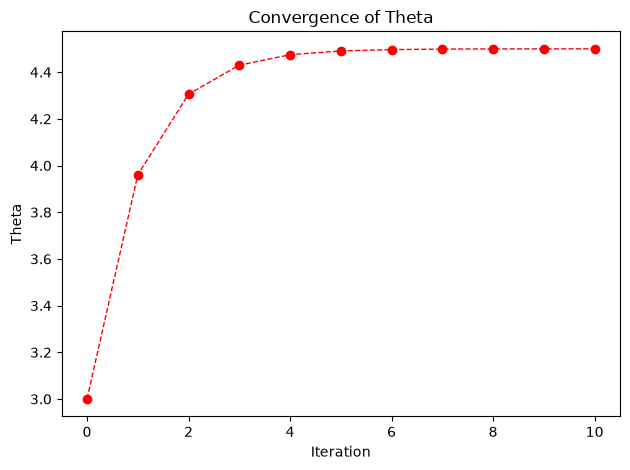

In [23]:
iterations = range(len(theta_history))
x = iterations
y = theta_history
plt.plot(x,
         y,
         color="red",
         linestyle="--",
         linewidth=1,
         marker="o"
)
plt.xlabel("Iteration")
plt.ylabel("Theta")
plt.title("Convergence of Theta")
plt.tight_layout()
plt.show()

The x-axis represents the iterations, while the y-axis represents the value of $\theta$. Overall, $\theta$ increases as the number of iterations increases. At the beginning, $\theta$ changes rapidly, while in the later iterations the changes become smaller. Since $\theta$ is getting closer to $4.5$ and the changes are becoming smaller, this indicates that gradient descent is converging toward the optimal value.

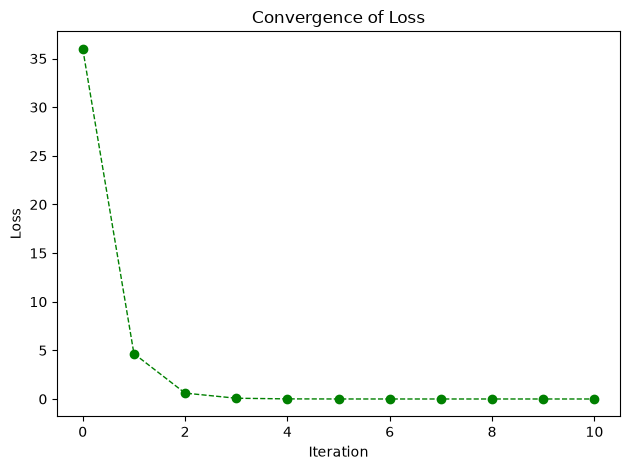

In [24]:
iterations = range(len(theta_history))
x = iterations
y = loss_history
plt.plot(x,
         y,
         color="green",
         linestyle="--",
         linewidth=1,
         marker="o"
)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Convergence of Loss")
plt.tight_layout()
plt.show()

The x-axis represents the iterations, while the y-axis represents the loss. Overall, loss decreases as the number of iterations increases. At the beginning, loss decreases rapidly, while in the later iterations the changes become smaller. Since loss is getting closer to $0$ and the changes are becoming smaller, this indicates that gradient descent is converging toward the minimum loss.

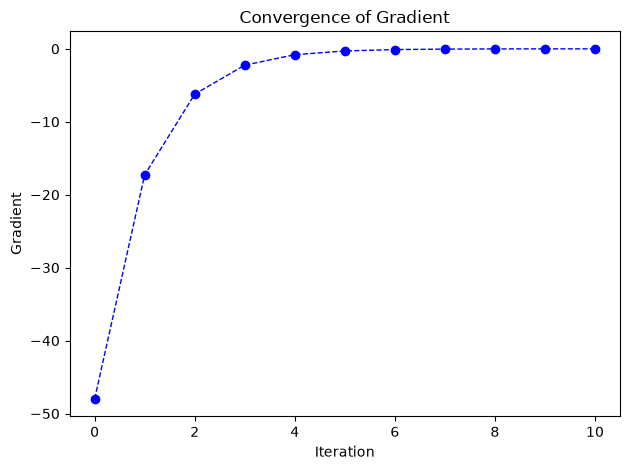

In [25]:
iterations = range(len(theta_history))
x = iterations
y = gradient_history
plt.plot(x,
         y,
         color="blue",
         linestyle="--",
         linewidth=1,
         marker="o"
)
plt.xlabel("Iteration")
plt.ylabel("Gradient")
plt.title("Convergence of Gradient")
plt.tight_layout()
plt.show()

The x-axis represents the iterations, while the y-axis represents the gradient. Overall, the gradient increases from a large negative value toward zero as the number of iterations increases. At the beginning, the gradient changes rapidly, while in the later iterations the changes become much smaller. Since the gradient is getting closer to zero, this indicates that $\theta$ is approaching a point where the loss function has a minimum.

## Numerical Gradient

In [26]:
def numerical_gradient(theta, h):
    return (loss(theta + h) - loss(theta - h)) / (2 * h)
h = 0.0001
print(numerical_gradient(3, h))

-48.000000000101295


The numerical gradient is approximately equal to the analytical gradient. This close agreement confirms that the analytical gradient has been implemented correctly.

## Gradient chcek

In [27]:
difference = abs(gradient(3) - numerical_gradient(3, h))
print(difference)

1.0129497240995988e-10


The absolute difference between the analytical and numerical gradients is extremely small, indicating that both methods produce almost the same gradient. This confirms that the analytical gradient implementation is correct.

## Learning Rate Experiment

To make the comparison fair, the starting value of $\theta$ and the number of iterations are kept the same for every experiment. The learning rate is the only factor that changes, allowing us to observe how different learning rates affect the convergence of gradient descent.

In [28]:
def run_gradient_descent(learning_rate, iterations):
    theta = 3
    loss_history = [loss(theta)]
    for i in range(iterations):
        theta = theta - learning_rate * gradient(theta)
        loss_history.append(loss(theta))
    return loss_history


In [29]:
num_iterations = 20
loss_005 = run_gradient_descent(0.005, num_iterations)
print(loss_005[0])
print(loss_005[-1])

36
0.033687900310196625


In [30]:
loss_02 = run_gradient_descent(0.02, num_iterations)

print(loss_02[0])
print(loss_02[-1])

36
6.4328360371142e-17


In [31]:
loss_05 = run_gradient_descent(0.05, num_iterations)

print(loss_05[0])
print(loss_05[-1])

36
4.8122980339788075e-08


In [32]:
loss_07 = run_gradient_descent(0.07, num_iterations)

print(loss_07[0])
print(loss_07[-1])

36
196412.85445329963


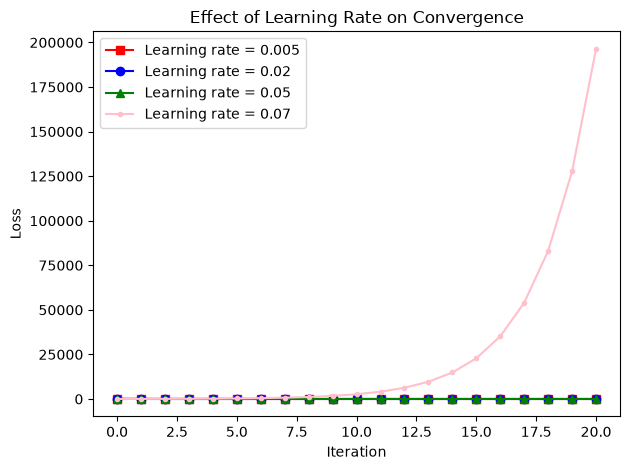

In [33]:
experiment_iterations = range(num_iterations + 1)
plt.plot(experiment_iterations, loss_005, label="Learning rate = 0.005", color="red", marker="s")
plt.plot(experiment_iterations, loss_02, label="Learning rate = 0.02", color="blue", marker="o")
plt.plot(experiment_iterations, loss_05, label="Learning rate = 0.05", color="green", marker="^")
plt.plot(experiment_iterations, loss_07, label="Learning rate = 0.07", color="pink", marker=".")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.tight_layout()
plt.show()

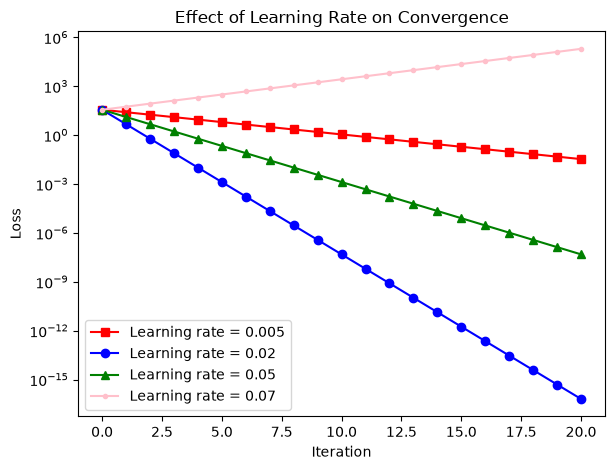

In [34]:
experiment_iterations = range(num_iterations + 1)
plt.plot(experiment_iterations, loss_005, label="Learning rate = 0.005", color="red", marker="s")
plt.plot(experiment_iterations, loss_02, label="Learning rate = 0.02", color="blue", marker="o")
plt.plot(experiment_iterations, loss_05, label="Learning rate = 0.05", color="green", marker="^")
plt.plot(experiment_iterations, loss_07, label="Learning rate = 0.07", color="pink", marker=".")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.tight_layout()
plt.yscale("log")
plt.show()

The linear-scale graph clearly shows that a learning rate of $0.07$ causes divergence, while the other learning rates converge. However, because the loss for $0.07$ becomes very large, the converging curves are difficult to compare on the linear scale. The logarithmic-scale graph makes these curves easier to examine and shows that, among the tested learning rates, $0.02$ provides the fastest stable convergence.

## Comparison with Scipy Optimization

In [35]:
from scipy import optimize
result = optimize.minimize_scalar(loss)
print(result.x)
print(result.fun)

4.5
0.0


In [36]:
custom_theta = theta_history[-1]
scipy_theta = result.x
print(custom_theta)
print(scipy_theta)
difference = abs(custom_theta - scipy_theta)
print(difference)

4.499945157623399
4.5
5.484237660091651e-05


The custom gradient descent produced a value of $\theta$ very close to the value found by SciPy. The very small absolute difference shows that the custom implementation successfully approximates the optimal solution.

## Result and Discussion
- The custom gradient descent produced a final value of $\theta \approx 4.499945$. This value is very close to the optimal value of $4.5$, indicating that the algorithm successfully converged toward the minimum.
- At the beginning, when $\theta=3$, the loss was $36$. As gradient descent updated $\theta$ toward the optimal value, the loss decreased and became almost zero. This shows that the optimization process successfully minimized the loss function.
- At $\theta=3$, the analytical gradient was $-48$, while the numerical gradient was approximately $-48.000000000101295$. Since these values are almost identical, the numerical gradient confirms that the analytical gradient was calculated and implemented correctly.
- With a learning rate of $0.005$, gradient descent converged, but the loss decreased relatively slowly.
- With a learning rate of $0.02$, the loss decreased much faster. Among the tested learning rates, $0.02$ produced the fastest stable convergence.
- With a learning rate of $0.05$, gradient descent also converged, but the parameter overshot the optimum and oscillated around it while gradually moving closer.
- With a learning rate of $0.07$, the loss increased instead of decreasing, indicating that gradient descent diverged. This shows that a learning rate that is too large can make the optimization unstable.
- The custom gradient descent produced a value of $\theta \approx 4.499945$, while SciPy returned $\theta = 4.5$. The absolute difference between the two results was approximately $5.48 \times 10^{-5}$, which is very small. This shows that the custom gradient descent implementation produced a result very close to the solution obtained by SciPy.

## Conclusion

The objective of this project was to find the value of $\theta$ that minimizes the loss function using gradient descent and to compare the analytical gradient with the numerical gradient.
The custom gradient descent produced a final value of $\theta \approx 4.499945$, which was very close to the optimal value of $4.5$. As $\theta$ approached the optimum, the loss became almost zero.
The analytical and numerical gradients were almost identical, which helped verify that the analytical gradient was calculated and implemented correctly. In addition, the custom gradient descent solution was very close to the solution obtained using SciPy.
Overall, this project demonstrated that the learning rate strongly affects the convergence speed and stability of gradient descent. A suitable learning rate allows the algorithm to converge efficiently, while a learning rate that is too large can cause instability or divergence.